In [1]:
import os, sys, json, time, shutil, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REQUIRED = ["Nhanh_AB_scaled/common_eval.py", "week05_Khoa/feature_list.json", "cic_ids_2017_cleaned.parquet",
            "outputs/baseline/split_indices.npz", "outputs/baseline/xgboost_model.joblib",
            "outputs/baseline/random_forest_model.joblib", "outputs/baseline/lightgbm_model.joblib"]

BASE_DIR_OVERRIDE = "" 
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

def find_base_dir():
    if BASE_DIR_OVERRIDE:
        return Path(BASE_DIR_OVERRIDE)
    if os.environ.get("AB_BASE"):
        return Path(os.environ["AB_BASE"])
    if not IN_COLAB:
        return Path(r"E:\Thuc tap")
    for root in ("/content/drive/MyDrive", "/content/drive/Shareddrives", "/content/drive/.shortcut-targets-by-id"):
        for depth in range(6):
            hits = glob.glob(os.path.join(root, *(["*"] * depth), "Nhanh_AB_scaled", "common_eval.py"))
            if hits:
                return Path(hits[0]).parent.parent
    raise FileNotFoundError("Không tìm thấy Nhanh_AB_scaled/common_eval.py trên Drive. Tải cả thư mục Nhanh_AB_scaled lên "
                            "Drive (cùng cấp với train_val_test_scaled, tuan4_Trung, ...) hoặc điền BASE_DIR_OVERRIDE.")

BASE_DIR = find_base_dir()
NAB_DIR = BASE_DIR / "Nhanh_AB_scaled"
os.environ["AB_BASE"] = str(BASE_DIR)
if str(NAB_DIR) not in sys.path:
    sys.path.insert(0, str(NAB_DIR))
missing = [f for f in REQUIRED if not (BASE_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu file trong {BASE_DIR}:\n  " + "\n  ".join(missing))
import importlib, common_eval as L
importlib.reload(L)

SMOKE = int(os.environ.get("AB_SMOKE", 0))
DA, DB = L.out_dir("A", bool(SMOKE)), L.out_dir("B", bool(SMOKE))
CMP = L.out_dir("C_compare", bool(SMOKE))
mA = json.loads((DA / "run_manifest.json").read_text(encoding="utf-8"))
mB = json.loads((DB / "run_manifest.json").read_text(encoding="utf-8"))
tA, tB = pd.read_csv(DA / "metrics_test.csv"), pd.read_csv(DB / "metrics_test.csv")
pd.set_option("display.width", 220)
print("Nhánh A hạng 1:", mA["best"], "| Nhánh B hạng 1:", mB["best"])
assert mA["params"] == mB["params"], "Hai nhánh KHÔNG dùng cùng tham số!"
print("Kiểm tra: hai nhánh dùng cùng tham số (PARAMS) -> OK")

Nhánh A hạng 1: xgboost | Nhánh B hạng 1: xgboost
Kiểm tra: hai nhánh dùng cùng tham số (PARAMS) -> OK


## Bảng 1. Hai nhánh


=== Bảng 1. Cùng 3 mô hình, cùng tham số – Nhánh A (tấn công chưa thấy) và Nhánh B (tấn công đã biết) ===
                             recall @FPR≤0,1%  FPR @FPR≤0,1%  recall @FPR≤1%  recall @0,5  PR-AUC  ROC-AUC  recall TB theo loại  recall bỏ loại đông nhất loại đông nhất (tỉ lệ)
nhánh         model                                                                                                                                                             
A – theo ngày xgboost                  0.9344         0.0013          0.9378       0.0109  0.9792   0.9933               0.2807                    0.0848             DDoS (93%)
              random_forest            0.9441         0.0020          0.9561       0.6666  0.9629   0.9778               0.4282                    0.2169             DDoS (93%)
              lightgbm                 0.9318         0.0013          0.9440       0.0000  0.9715   0.9874               0.5112                    0.0618             DDoS (93%)
B – 70/1

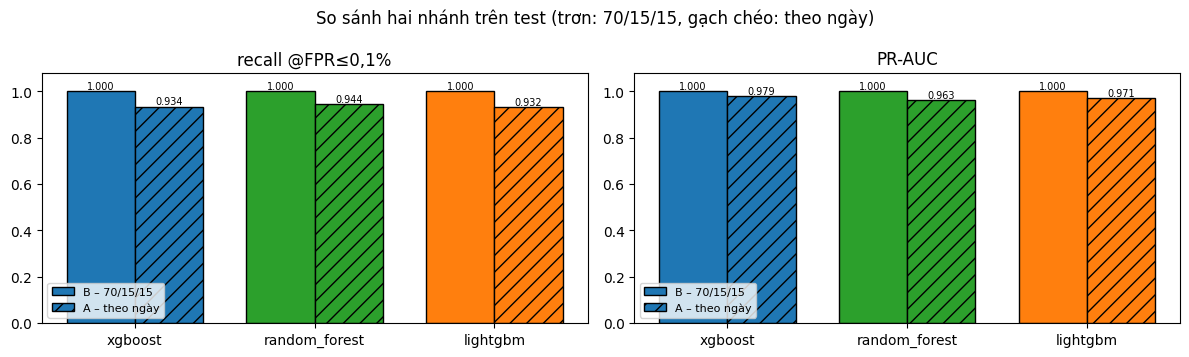

In [2]:
rows = []
for br, t in (("A – theo ngày", tA), ("B – 70/15/15", tB)):
    a = t[t.scope == "ALL"]
    for m in L.MODELS:
        x = a[a.model == m].set_index("rule")
        rows.append({"nhánh": br, "model": m, "recall @FPR≤0,1%": x.loc["fpr0.1%", "recall"], "FPR @FPR≤0,1%": x.loc["fpr0.1%", "fpr"],
                     "recall @FPR≤1%": x.loc["fpr1%", "recall"], "recall @0,5": x.loc["0.5", "recall"],
                     "PR-AUC": x.pr_auc.iloc[0], "ROC-AUC": x.roc_auc.iloc[0]})
    pts = L.per_type_summary(t)
    for r in rows[-3:]:
        r["recall TB theo loại"] = pts.loc[r["model"], "recall TB theo loại @fpr0.1%"]
        r["recall bỏ loại đông nhất"] = pts.loc[r["model"], "recall bỏ loại đông nhất @fpr0.1%"]
        r["loại đông nhất (tỉ lệ)"] = f'{pts.loc[r["model"], "loại đông nhất"]} ({pts.loc[r["model"], "tỉ lệ loại đông nhất"]:.0%})'
t1 = pd.DataFrame(rows).set_index(["nhánh", "model"])
t1.to_csv(CMP / "bang1_hai_nhanh.csv", float_format="%.6f", encoding="utf-8-sig")
L.show(t1, "Bảng 1. Cùng 3 mô hình, cùng tham số – Nhánh A (tấn công chưa thấy) và Nhánh B (tấn công đã biết)", 4)
num = ["recall @FPR≤0,1%", "recall TB theo loại", "recall bỏ loại đông nhất", "recall @0,5", "PR-AUC"]
d = (t1.xs("B – 70/15/15")[num] - t1.xs("A – theo ngày")[num])
L.show(d, "Mức giảm khi chuyển từ tấn công đã biết (B) sang chưa thấy (A)", 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col in zip(axes, ("recall @FPR≤0,1%", "PR-AUC")):
    x = np.arange(len(L.MODELS)); w = 0.38
    for k, (br, hatch) in enumerate((("B – 70/15/15", ""), ("A – theo ngày", "//"))):
        v = t1.xs(br)[col].reindex(L.MODELS).values
        ax.bar(x + (k - 0.5) * w, v, w, color=[L.COLORS[m] for m in L.MODELS], hatch=hatch, edgecolor="k", label=br)
        for i, y in enumerate(v):
            ax.text(x[i] + (k - 0.5) * w, y, f"{y:.3f}", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, L.MODELS); ax.set_title(col); ax.legend(fontsize=8); ax.set_ylim(0, 1.08)
fig.suptitle("So sánh hai nhánh trên test (trơn: 70/15/15, gạch chéo: theo ngày)"); fig.tight_layout()
fig.savefig(CMP / "hai_nhanh.png", bbox_inches="tight"); plt.show()

## Bảng 2. Mô hình đã khóa so với Nhánh B

In [3]:
import joblib
df = L.load_dedup(); F = L.feature_order(); idx = np.load(BASE_DIR / "outputs" / "baseline" / "split_indices.npz")
predB = pd.read_parquet(DB / "test_predictions.parquet")
te_ids = predB.flow_id.to_numpy()
va_ids = idx["val"] if not SMOKE else np.sort(np.random.RandomState(0).choice(idx["val"], SMOKE, replace=False))
Xte, yte = df.loc[te_ids, F].to_numpy(np.float32), df.Label_binary.to_numpy()[te_ids]
Xva, yva = df.loc[va_ids, F].to_numpy(np.float32), df.Label_binary.to_numpy()[va_ids]
locked_thr = json.loads((BASE_DIR / "outputs" / "baseline" / "thresholds.json").read_text())["models"]["xgboost"]["threshold"]
del df
rows = []
for m in L.MODELS:
    mdl = joblib.load(BASE_DIR / "outputs" / "baseline" / f"{m}_model.joblib")["model"]
    pv, pt = mdl.predict_proba(Xva)[:, 1], mdl.predict_proba(Xte)[:, 1]
    thr = L.thresholds_from_val(yva, pv)
    b = tB[(tB.model == m) & (tB.scope == "ALL")].set_index("rule")
    pb = predB[f"p_{m}"].to_numpy()
    for r in L.RULES:
        lk = L._bin_row(yte, pt >= thr[r]); yb = pb >= b.loc[r, "threshold"]
        rows.append({"model": m, "rule": L.RULE_VI[r], "đã khóa: recall": lk["recall"], "đã khóa: FPR": lk["fpr"],
                     "B (scale): recall": b.loc[r, "recall"], "B (scale): FPR": b.loc[r, "fpr"],
                     "Δ recall": b.loc[r, "recall"] - lk["recall"],
                     "số flow khác quyết định": int(((pt >= thr[r]) != yb).sum()), "trên tổng": len(yte)})
    if m == "xgboost":
        lk = L._bin_row(yte, pt >= locked_thr)
        rows.append({"model": m, "rule": f"đã khóa {locked_thr:.4f}", "đã khóa: recall": lk["recall"], "đã khóa: FPR": lk["fpr"]})
t2 = pd.DataFrame(rows).set_index(["model", "rule"])
t2.to_csv(CMP / "bang2_khoa_vs_B.csv", float_format="%.6f", encoding="utf-8-sig")
L.show(t2, "Bảng 2. Mô hình đã khóa (gốc) so với Nhánh B (đã scale) – cùng tập test 70/15/15", 5)


=== Bảng 2. Mô hình đã khóa (gốc) so với Nhánh B (đã scale) – cùng tập test 70/15/15 ===
                              đã khóa: recall  đã khóa: FPR  B (scale): recall  B (scale): FPR  Δ recall  số flow khác quyết định  trên tổng
model         rule                                                                                                                          
xgboost       FPR ≤ 1%                1.00000       0.01080            0.99998         0.01020  -0.00002                   1914.0   260632.0
              FPR ≤ 0,1%              0.99995       0.00109            0.99979         0.00111  -0.00017                    160.0   260632.0
              0,5                     0.99981       0.00038            0.99964         0.00049  -0.00017                     38.0   260632.0
              đã khóa 0.0025          1.00000       0.00362                NaN             NaN       NaN                      NaN        NaN
random_forest FPR ≤ 1%                1.00000       0.00655     

## Bảng 3. Ảnh hưởng của bước scale ở nhánh theo ngày

In [4]:
old = BASE_DIR / "Nhanh_A_B" / "outputs" / "B" / "binary_metrics_test.csv"
if old.exists() and not SMOKE:
    o = pd.read_csv(old); o = o[o.scope == "ALL"].set_index(["model", "rule"])
    n = tA[tA.scope == "ALL"].set_index(["model", "rule"])
    t3 = pd.DataFrame({"gốc 31/10: recall": o.recall, "đã scale: recall": n.recall,
                       "gốc 31/10: PR-AUC": o.pr_auc, "đã scale: PR-AUC": n.pr_auc})
    t3["Δ recall"] = t3["đã scale: recall"] - t3["gốc 31/10: recall"]
    t3.to_csv(CMP / "bang3_theo_ngay_goc_vs_scale.csv", float_format="%.6f", encoding="utf-8-sig")
    L.show(t3, "Bảng 3. Nhánh theo ngày: dữ liệu gốc (31/10) so với đã scale (hôm nay)", 4)
    print("Lưu ý: mô hình cây về lý thuyết không đổi khi scale (biến đổi đơn điệu từng cột); chênh lệch ở đây đến từ làm tròn float32\n"
          "và từ việc ngưỡng chọn trên validation cùng ngày rất nhạy (kết quả 5 seed trong Week_new/branch_AB cho thấy Recall @FPR≤0,1%\n"
          "của LightGBM dao động 0,06–0,89 chỉ do đổi seed chia validation). Không nên kết luận 'scale làm LightGBM tốt lên'.")
else:
    print("Bỏ qua (không có kết quả 31/10 hoặc đang chạy thử).")


=== Bảng 3. Nhánh theo ngày: dữ liệu gốc (31/10) so với đã scale (hôm nay) ===
                       gốc 31/10: recall  đã scale: recall  gốc 31/10: PR-AUC  đã scale: PR-AUC  Δ recall
model         rule                                                                                       
xgboost       fpr1%               0.9366            0.9378             0.9748            0.9792    0.0012
              fpr0.1%             0.9343            0.9344             0.9748            0.9792    0.0001
              0.5                 0.0006            0.0109             0.9748            0.9792    0.0103
random_forest fpr1%               0.9897            0.9561             0.9898            0.9629   -0.0336
              fpr0.1%             0.9473            0.9441             0.9898            0.9629   -0.0031
              0.5                 0.0968            0.6666             0.9898            0.9629    0.5699
lightgbm      fpr1%               0.9425            0.9440             0

## Kết luận tự động

In [5]:
bA, bB = mA["best"], mB["best"]
x = t1.xs("A – theo ngày")["recall @FPR≤0,1%"]; y = t1.xs("B – 70/15/15")["recall @FPR≤0,1%"]
r0 = tB[(tB.scope == "ALL")].iloc[0]; n_att = int(r0.tp + r0.fn)
print(f"1. Nhánh B (70/15/15): hạng 1 = {bB}; recall @FPR≤0,1%: " + ", ".join(f"{m} {v:.4f}" for m, v in y.items())
      + f" -> chênh lệch lớn nhất {y.max() - y.min():.4f} ≈ {round((y.max() - y.min()) * n_att)} / {n_att:,} flow tấn công.")
print(f"2. Nhánh A (theo ngày): hạng 1 theo validation = {bA}; trên test tốt nhất = {x.idxmax()} ({x.max():.4f}), "
      f"kém nhất = {x.idxmin()} ({x.min():.4f})" + ("." if x.idxmax() == bA else
      " -> validation cùng ngày không chọn được mô hình tổng quát tốt nhất (xem thêm LOFO ở notebook A)."))
pa_ = t1.xs("A – theo ngày")
print(f"   Nhưng ở Nhánh A, loại đông nhất chiếm phần lớn test ({pa_['loại đông nhất (tỉ lệ)'].iloc[0]}): bỏ loại này thì recall chỉ còn "
      + ", ".join(f"{m} {v:.3f}" for m, v in pa_["recall bỏ loại đông nhất"].items()) + " -> tấn công mới khác loại hầu như bị bỏ lọt.")
d2 = t2.xs("xgboost").loc["FPR ≤ 0,1%"]
small = abs(d2["Δ recall"]) < 1e-3
print(f"3. XGBoost đã khóa so với XGBoost Nhánh B (ngưỡng FPR ≤ 0,1%): {int(d2['số flow khác quyết định']):,} / "
      f"{int(d2['trên tổng']):,} flow khác quyết định, Δ recall = {d2['Δ recall']:+.5f} -> "
      + ("bước scale không đổi kết luận; mô hình đã khóa giữ nguyên làm mục tiêu Robustness."
         if small else "chênh lệch đáng kể, cần xem lại trước khi kết luận."))
print("\nCác bảng và biểu đồ:", CMP)

1. Nhánh B (70/15/15): hạng 1 = xgboost; recall @FPR≤0,1%: xgboost 0.9998, random_forest 1.0000, lightgbm 0.9998 -> chênh lệch lớn nhất 0.0002 ≈ 8 / 42,169 flow tấn công.
2. Nhánh A (theo ngày): hạng 1 theo validation = xgboost; trên test tốt nhất = random_forest (0.9441), kém nhất = lightgbm (0.9318) -> validation cùng ngày không chọn được mô hình tổng quát tốt nhất (xem thêm LOFO ở notebook A).
   Nhưng ở Nhánh A, loại đông nhất chiếm phần lớn test (DDoS (93%)): bỏ loại này thì recall chỉ còn xgboost 0.085, random_forest 0.217, lightgbm 0.062 -> tấn công mới khác loại hầu như bị bỏ lọt.
3. XGBoost đã khóa so với XGBoost Nhánh B (ngưỡng FPR ≤ 0,1%): 160 / 260,632 flow khác quyết định, Δ recall = -0.00017 -> bước scale không đổi kết luận; mô hình đã khóa giữ nguyên làm mục tiêu Robustness.

Các bảng và biểu đồ: E:\Thuc tap\Nhanh_AB_scaled\outputs\C_compare
